# 08 - Coded BER and sentence BLER for the six MCSs (Task 1a, 1b)
**Objective.** (a) Validate the simulator with uncoded BER against theory, then (b) evaluate coded BER and sentence BLER for QPSK 1/2, QPSK 3/4, 16-QAM 1/2, 16-QAM 3/4, 64-QAM 2/3, 64-QAM 3/4 over AWGN and Rayleigh block fading.

**Definitions.**
* *Coded BER* = fraction of wrong **information bits** after Viterbi decoding (the Huffman bits).
* *Sentence BLER* = fraction of sentences whose reconstructed text differs from the transmitted text.
* Each Monte-Carlo point sends the same test sentences several times with fresh noise/fading realisations; every point has a fixed seed so results are reproducible. 95 % Wilson confidence intervals are stored in the CSV.

> Results come from `python main.py --experiment mcs --mode quick|full`. The cell below states which mode is loaded.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import experiments as ex, plotting
MODE = ex.best_available_mode(ROOT)      # "full" once `python main.py --experiment all --mode full` has finished
# MODE = "quick"                         # <- uncomment to force the small debugging data set
print("Using", MODE.upper(), "results", "" if MODE == "full" else "(QUICK MODE: small sample, NOT final results)")
sweep = pd.read_csv(TAB / f"{MODE}_mcs_sweep.csv")
cfg = ex.CONFIG[MODE]
print(f"{len(sweep)} (channel, MCS, SNR) points; {cfg['n_sentences']} sentences x {cfg['reps_awgn']} (AWGN) / {cfg['reps_rayleigh']} (Rayleigh) repetitions per point")

Using FULL results 
528 (channel, MCS, SNR) points; 2000 sentences x 3 (AWGN) / 5 (Rayleigh) repetitions per point


/home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Validation first: uncoded BER vs theory (Task 1a)

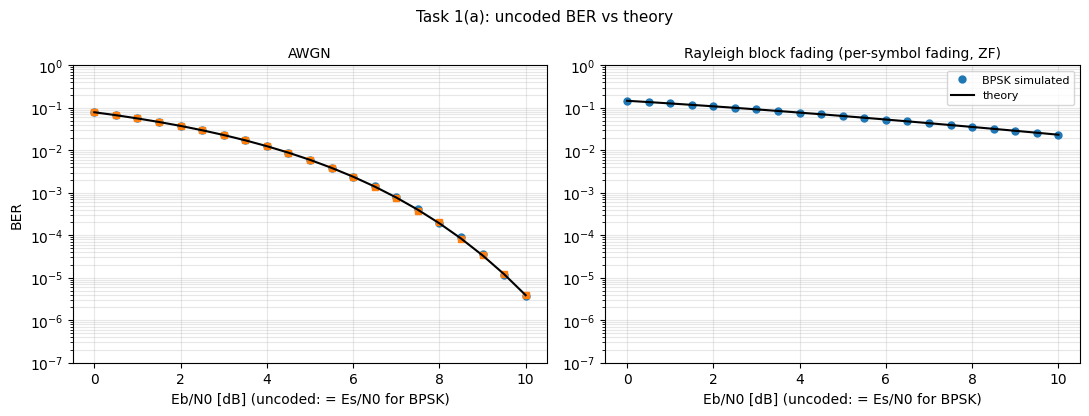

points: 63 | within 95% CI or 5 %: 63 | max |rel. error| for points with >=400 errors: 7.64 %


,modulation,channel,ebn0_db,n_bits,n_errors,ber_sim,ber_theory,rel_err_%
0,BPSK,awgn,0.0,1000000,78926,0.078926,0.078650,0.351428
4,BPSK,awgn,2.0,1000000,37687,0.037687,0.037506,0.482246
8,BPSK,awgn,4.0,1000000,12567,0.012567,0.012501,0.529421
12,BPSK,awgn,6.0,1000000,2325,0.002325,0.002388,-2.650045
16,BPSK,awgn,8.0,3000000,577,0.000192,0.000191,0.746727
20,BPSK,awgn,10.0,100000000,366,0.000004,0.000004,-5.477848
24,QPSK,awgn,1.5,1000000,46352,0.046352,0.046401,-0.106195
28,QPSK,awgn,3.5,1000000,17344,0.017344,0.017173,0.998445
32,QPSK,awgn,5.5,1000000,3895,0.003895,0.003862,0.848431
36,QPSK,awgn,7.5,2000000,751,0.000376,0.000399,-5.841662


In [3]:
unc = pd.read_csv(TAB / f"{MODE}_uncoded_ber.csv")
plotting.plot_uncoded(unc, MODE, FIG / f"{MODE}_uncoded_ber.png"); plt.show()
unc["rel_err_%"] = 100 * (unc.ber_sim / unc.ber_theory - 1)
print("points:", len(unc), "| within 95% CI or 5 %:", int(unc.inside_ci_or_5pct.sum()), "| max |rel. error| for points with >=400 errors: %.2f %%" % unc[unc.n_errors >= 400]["rel_err_%"].abs().max())
display(unc[["modulation", "channel", "ebn0_db", "n_bits", "n_errors", "ber_sim", "ber_theory", "rel_err_%"]].iloc[::4])
assert unc.inside_ci_or_5pct.all(), "validation failed - do not trust the coded results"

Validation passed (BPSK and QPSK over AWGN, BPSK over Rayleigh with ZF) - the noise scaling, fading generator, equaliser and BER counting are correct, so the coded experiments can be trusted.

## 2. Coded BER and sentence BLER vs SNR

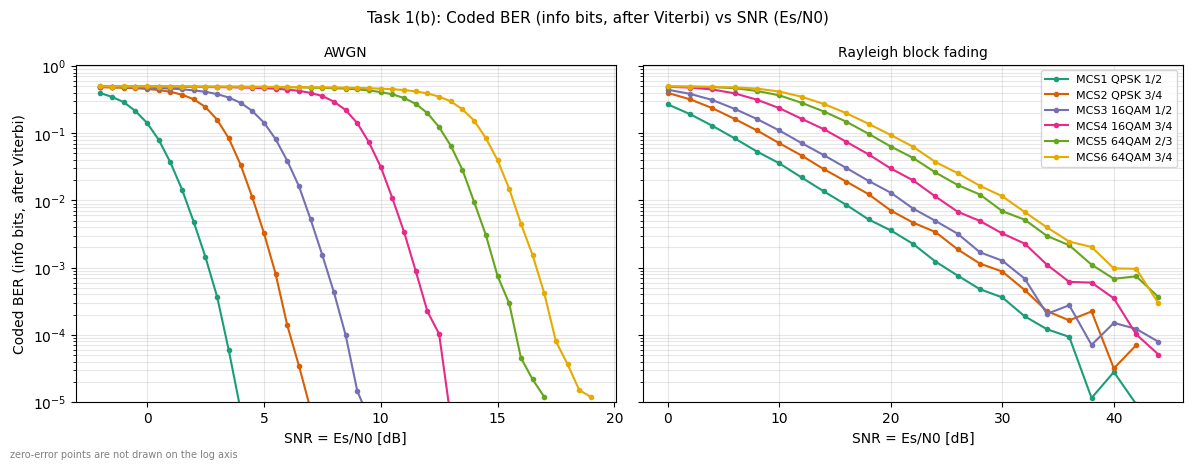

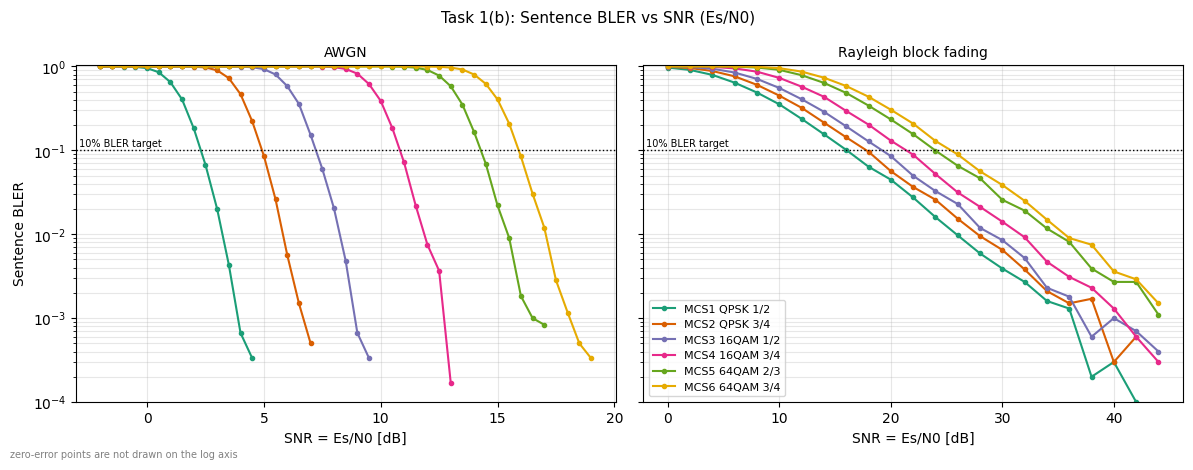

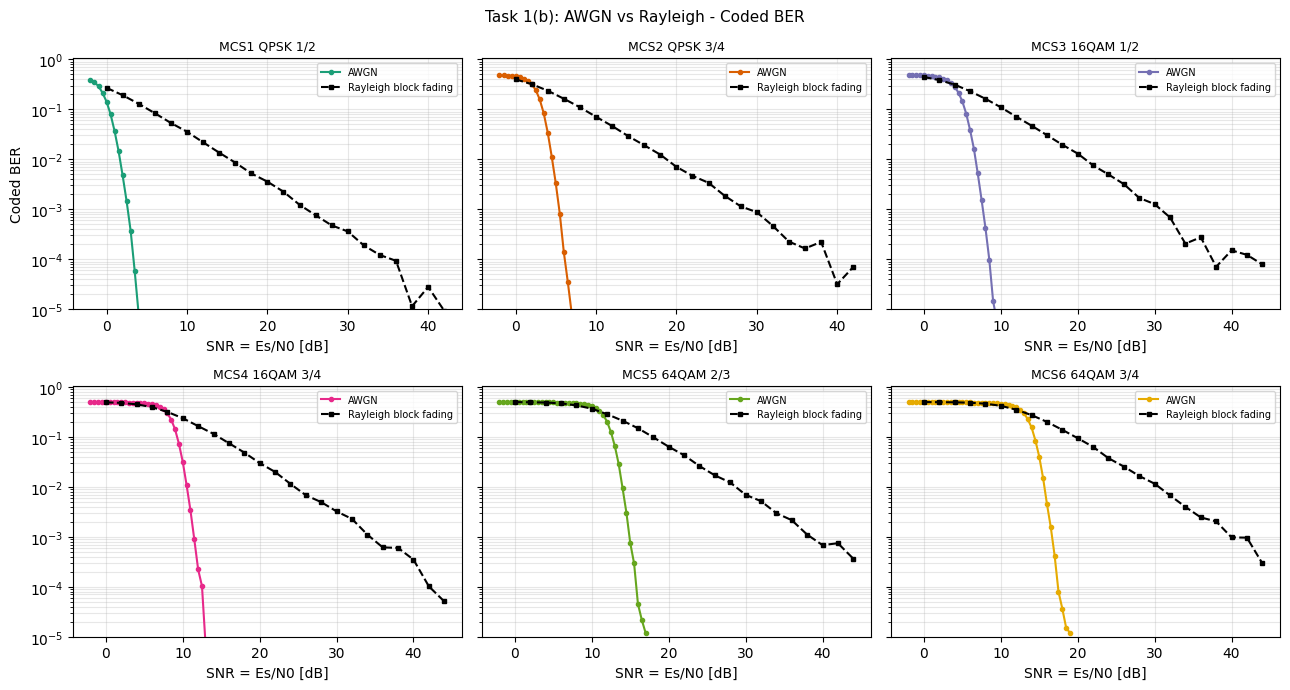

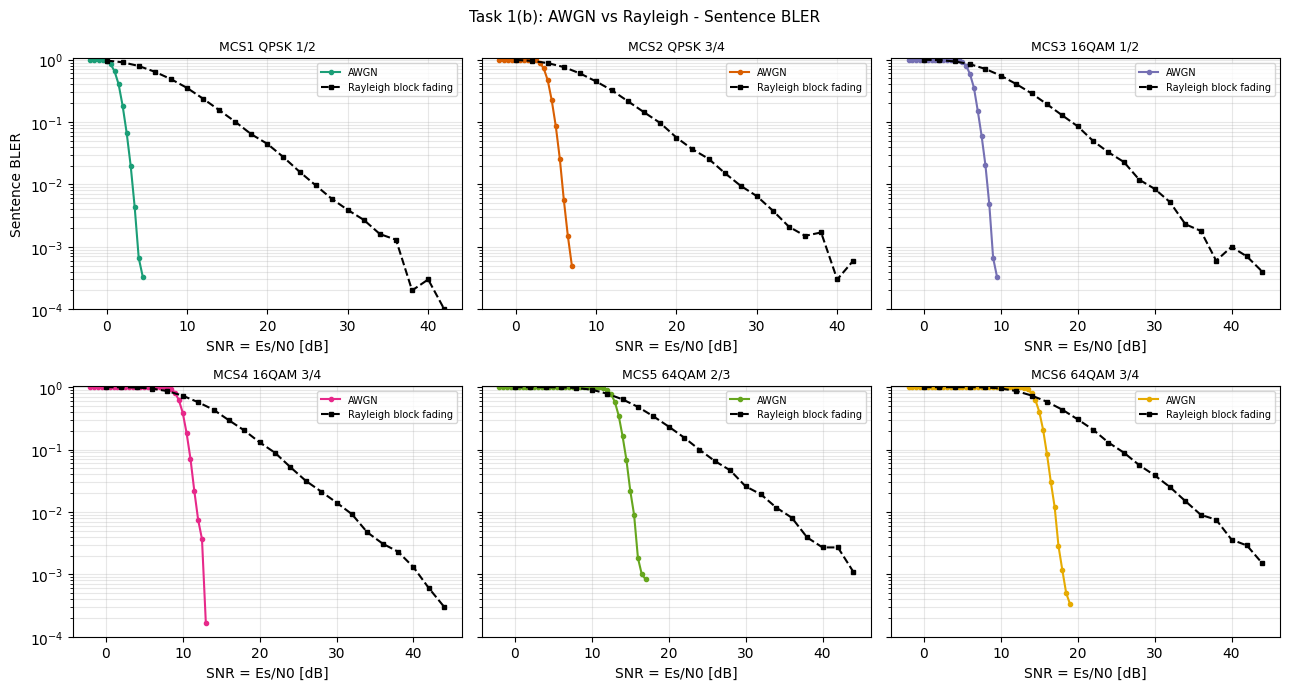

In [4]:
figs = plotting.plot_ber_bler(sweep, MODE, str(FIG / MODE)); plt.show()

### AWGN vs Rayleigh, per MCS

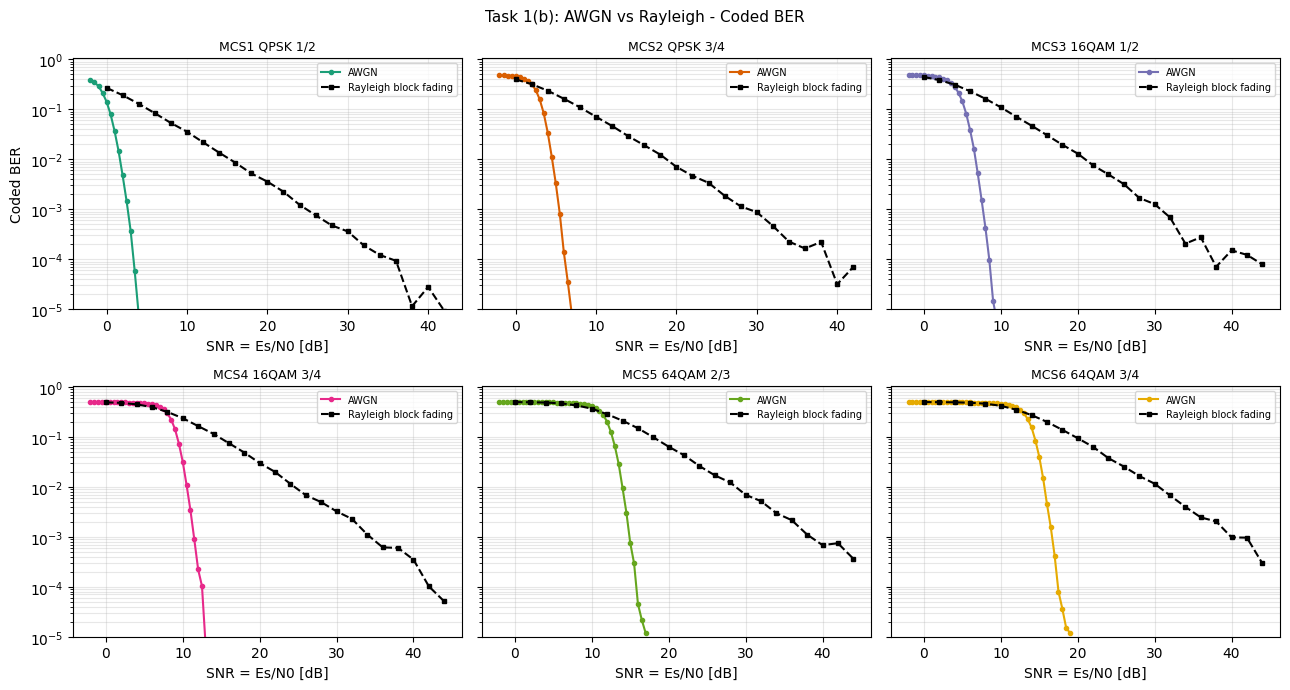

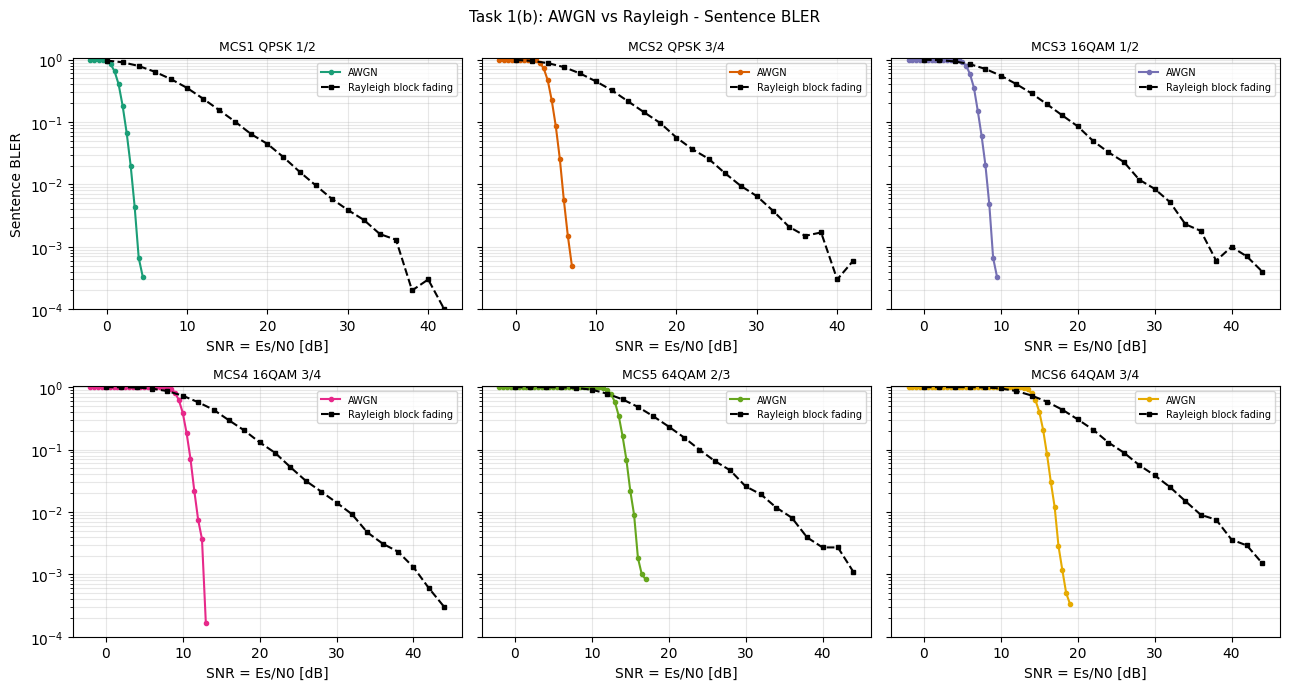

In [5]:
for k in ("coded_ber_awgn_vs_rayleigh", "bler_awgn_vs_rayleigh"): display(figs[k])

## 3. Quantitative summary from the data

In [6]:
def snr_at(d, col, target):
    """smallest SNR (linear interpolation in the SNR grid) at which `col` first falls to <= target"""
    d = d.sort_values("snr_db"); s, v = d.snr_db.values, d[col].values
    k = np.flatnonzero(v <= target)
    if len(k) == 0: return np.nan
    k = k[0]
    if k == 0: return float(s[0])
    return float(s[k - 1] + (v[k - 1] - target) / (v[k - 1] - v[k]) * (s[k] - s[k - 1]))
rows = []
for m in sorted(sweep.mcs.unique()):
    r = dict(MCS=plotting.LABEL[m])
    for chn in ("awgn", "rayleigh"):
        d = sweep[(sweep.channel == chn) & (sweep.mcs == m)]
        r[f"SNR@BLER=10% {chn} [dB]"] = snr_at(d, "bler", 0.10); r[f"SNR@BLER=1% {chn} [dB]"] = snr_at(d, "bler", 0.01)
    rows.append(r)
summary = pd.DataFrame(rows).set_index("MCS").round(2); display(summary); summary.to_csv(TAB / f"{MODE}_snr_thresholds.csv")
a, r_ = summary["SNR@BLER=10% awgn [dB]"], summary["SNR@BLER=10% rayleigh [dB]"]
print("\nSNR needed for BLER<=10 %: Rayleigh minus AWGN per MCS [dB]:", (r_ - a).round(1).tolist())
print("Spacing of AWGN thresholds between consecutive MCSs [dB]:", np.diff(a.values).round(1).tolist())

,SNR@BLER=10% awgn [dB],SNR@BLER=1% awgn [dB],SNR@BLER=10% rayleigh [dB],SNR@BLER=1% rayleigh [dB]
MCS,,,,
MCS1 QPSK 1/2,2.36,3.32,16.06,25.90
MCS2 QPSK 3/4,4.95,5.89,17.84,27.83
MCS3 16QAM 1/2,7.28,8.33,19.31,29.12
MCS4 16QAM 3/4,10.87,11.91,21.46,31.67
MCS5 64QAM 2/3,14.34,15.46,23.98,34.94
MCS6 64QAM 3/4,15.94,17.11,25.46,35.66



SNR needed for BLER<=10 %: Rayleigh minus AWGN per MCS [dB]: [13.7, 12.9, 12.0, 10.6, 9.6, 9.5]
Spacing of AWGN thresholds between consecutive MCSs [dB]: [2.6, 2.3, 3.6, 3.5, 1.6]


### Reading the plots
* **AWGN.** Every curve is a very steep "waterfall" (a few dB wide): above the threshold SNR the sentence is almost always perfect, below it almost always lost. Higher-order/higher-rate MCSs are shifted right by the amounts printed above.
* **Rayleigh block fading.** The curves are far shallower and need tens of dB more SNR for the same BLER. With one fade per RB and no interleaver, a sentence that falls into a deep-faded RB loses a burst of bits that the convolutional code cannot repair; the outage probability of a Rayleigh channel decays only like $1/\text{SNR}$ (10 dB per decade), which is exactly the slope visible in the BLER curves at high SNR.
* **Coded BER vs BLER.** BLER is much larger than BER where errors are bursty (see notebook 09).

## 4. Statistical reliability

In [7]:
s = sweep.copy(); s["resolution"] = 1 / s.n_frames
low = s[(s.bler > 0) & (s.n_block_errors < 10)]
print(f"{len(s)} points; frames per point: AWGN {s[s.channel == 'awgn'].n_frames.iloc[0]}, Rayleigh {s[s.channel == 'rayleigh'].n_frames.iloc[0]}")
print("smallest non-zero BLER resolvable: AWGN %.1e, Rayleigh %.1e" % (1 / s[s.channel == 'awgn'].n_frames.iloc[0], 1 / s[s.channel == 'rayleigh'].n_frames.iloc[0]))
print(f"points with 1-9 block errors (low statistical confidence, relative CI > ~60 %): {len(low)} of {len(s)}")
print("BLER = 0 means 'no block error observed in N frames'; the 95 % upper bound is about 3/N.")
if MODE != "full": print("\n*** QUICK MODE: only", s.n_frames.iloc[0], "frames per point - results are for debugging, not for claims. ***")
display(s[["channel", "mcs", "snr_db", "n_frames", "n_block_errors", "bler", "bler_ci_lo", "bler_ci_hi"]].query("0 < bler < 1").head(12))

528 points; frames per point: AWGN 6000, Rayleigh 10000
smallest non-zero BLER resolvable: AWGN 1.7e-04, Rayleigh 1.0e-04
points with 1-9 block errors (low statistical confidence, relative CI > ~60 %): 22 of 528
BLER = 0 means 'no block error observed in N frames'; the 95 % upper bound is about 3/N.


,channel,mcs,snr_db,n_frames,n_block_errors,bler,bler_ci_lo,bler_ci_hi
1,awgn,1,-1.5,6000,5999,0.999833,0.999056,0.999971
2,awgn,1,-1.0,6000,5982,0.997000,0.995263,0.998101
3,awgn,1,-0.5,6000,5927,0.987833,0.984731,0.990312
4,awgn,1,0.0,6000,5726,0.954333,0.948754,0.959331
5,awgn,1,0.5,6000,5114,0.852333,0.843131,0.861085
6,awgn,1,1.0,6000,3895,0.649167,0.636999,0.661143
7,awgn,1,1.5,6000,2422,0.403667,0.391317,0.416139
8,awgn,1,2.0,6000,1094,0.182333,0.172767,0.192306
9,awgn,1,2.5,6000,404,0.067333,0.061265,0.073955
10,awgn,1,3.0,6000,120,0.020000,0.016752,0.023862
